<a href="https://colab.research.google.com/github/techievansh/beauty-wellness-data-science-internship/blob/main/Week_05_Predictive_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Colab Notebooks/Dataset/beauty_reviews_cleaned.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Mounted at /content/drive
Dataset loaded successfully!
Dataset Shape: (10192, 12)


,user_id,item_id,rating,title,text,helpful_vote,verified_purchase,timestamp,review_date,title_clean,text_clean,review_length
0,AHCXZZ6R4US43PBVXXVN47OTTVHQ,B0002KHTCK,5.0,Best Toothbrush Available,I have been using the Braun Oral B 3D toothbru...,22,False,1103814114,2004-12-23 15:01:54+00:00,Best Toothbrush Available,I have been using the Braun Oral B 3D toothbru...,1966
1,AHUSGOTGVU5LFFPGCWLOTZ33RH7A,B0002KHTCK,5.0,Should have gotten this earlier,Just used this thing this morning and oh boy.....,7,False,1103819630,2004-12-23 16:33:50+00:00,Should have gotten this earlier,Just used this thing this morning and oh boy.....,394
2,AFL2ZDLKD6WRY5AG35RAWWKQTJFA,B000PKKAGO,4.0,Nice Shave...but beter than a razor?,At various times in my life I have rotated bet...,0,False,1197136923,2007-12-08 18:02:03+00:00,Nice Shave...but beter than a razor?,At various times in my life I have rotated bet...,1304
3,AG2C3CTEG3T7HPEKIZH2OQ54722Q,B000PKKAGO,5.0,Made me a Convert (from Razor Blades),I was skeptical about this shaver because of m...,1,False,1197389094,2007-12-11 16:04:54+00:00,Made me a Convert (from Razor Blades),I was skeptical about this shaver because of m...,2671
4,AHHWI6X47RXVMZOZCKRZCGZG36CQ,B000PKNPES,3.0,"Norelco is great, this one is just OK",I have used Norelco shavers for many years and...,19,False,1197724276,2007-12-15 13:11:16+00:00,"Norelco is great, this one is just OK",I have used Norelco shavers for many years and...,3554


In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nRating Distribution:")
print(df['rating'].value_counts().sort_index())

Columns:
['user_id', 'item_id', 'rating', 'title', 'text', 'helpful_vote', 'verified_purchase', 'timestamp', 'review_date', 'title_clean', 'text_clean', 'review_length']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10192 entries, 0 to 10191
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   user_id            10192 non-null  object 
 1   item_id            10192 non-null  object 
 2   rating             10192 non-null  float64
 3   title              10192 non-null  object 
 4   text               10192 non-null  object 
 5   helpful_vote       10192 non-null  int64  
 6   verified_purchase  10192 non-null  bool   
 7   timestamp          10192 non-null  int64  
 8   review_date        10192 non-null  object 
 9   title_clean        10192 non-null  object 
 10  text_clean         10182 non-null  object 
 11  review_length      10192 non-null  int64  
dtypes: bool(1), float64(1)

In [ ]:
def assign_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df['sentiment'] = df['rating'].apply(assign_sentiment)

print("Sentiment labels created successfully!")
print(df[['rating', 'sentiment']].head(10))

Sentiment labels created successfully!
   rating sentiment
0     5.0  Positive
1     5.0  Positive
2     4.0  Positive
3     5.0  Positive
4     3.0   Neutral
5     3.0   Neutral
6     3.0   Neutral
7     4.0  Positive
8     4.0  Positive
9     5.0  Positive


sentiment
Positive    8371
Neutral     1100
Negative     721
Name: count, dtype: int64


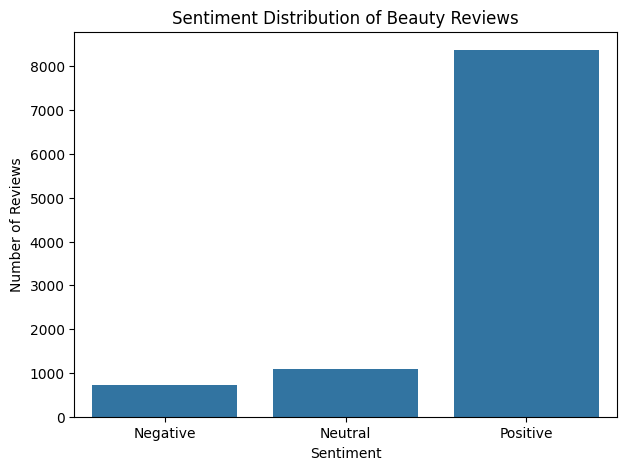

In [ ]:
sentiment_counts = df['sentiment'].value_counts()

print(sentiment_counts)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='sentiment', order=['Negative', 'Neutral', 'Positive'])
plt.title('Sentiment Distribution of Beauty Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [ ]:
print(df[['title_clean', 'text_clean']].head())

                             title_clean  \
0              Best Toothbrush Available   
1        Should have gotten this earlier   
2   Nice Shave...but beter than a razor?   
3  Made me a Convert (from Razor Blades)   
4  Norelco is great, this one is just OK   

                                          text_clean  
0  I have been using the Braun Oral B 3D toothbru...  
1  Just used this thing this morning and oh boy.....  
2  At various times in my life I have rotated bet...  
3  I was skeptical about this shaver because of m...  
4  I have used Norelco shavers for many years and...  


In [ ]:
df['combined_text'] = (
    df['title_clean'].fillna('').astype(str) + ' ' +
    df['text_clean'].fillna('').astype(str)
).str.strip()

df = df[df['combined_text'].str.len() > 0].copy()

print("Final Dataset Shape:", df.shape)
print(df[['combined_text', 'sentiment']].head())

Final Dataset Shape: (10192, 14)
                                       combined_text sentiment
0  Best Toothbrush Available I have been using th...  Positive
1  Should have gotten this earlier Just used this...  Positive
2  Nice Shave...but beter than a razor? At variou...  Positive
3  Made me a Convert (from Razor Blades) I was sk...  Positive
4  Norelco is great, this one is just OK I have u...   Neutral


In [ ]:
X = df['combined_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training samples: 8153
Testing samples: 2039

Training sentiment distribution:
sentiment
Positive    6696
Neutral      880
Negative     577
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Positive    1675
Neutral      220
Negative     144
Name: count, dtype: int64


In [ ]:
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF transformation completed!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF transformation completed!
Training matrix shape: (8153, 5000)
Testing matrix shape: (2039, 5000)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=30,
        class_weight='balanced',
        random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"{name} trained successfully!")

results_df = pd.DataFrame(results)
results_df = results_df.set_index("Model")

print("\nModel Training Completed!")
display(results_df.round(4))

Logistic Regression trained successfully!
Multinomial Naive Bayes trained successfully!
Decision Tree trained successfully!

Model Training Completed!


,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.7749,0.8289,0.7749,0.7966
Multinomial Naive Bayes,0.8225,0.8540,0.8225,0.7433
Decision Tree,0.7003,0.7667,0.7003,0.7268


In [ ]:
from sklearn.metrics import classification_report

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=['Negative', 'Neutral', 'Positive'],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.42      0.55      0.47       144
     Neutral       0.30      0.48      0.37       220
    Positive       0.93      0.83      0.88      1675

    accuracy                           0.77      2039
   macro avg       0.55      0.62      0.57      2039
weighted avg       0.83      0.77      0.80      2039


Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative       1.00      0.01      0.01       144
     Neutral       1.00      0.00      0.01       220
    Positive       0.82      1.00      0.90      1675

    accuracy                           0.82      2039
   macro avg       0.94      0.34      0.31      2039
weighted avg       0.85      0.82      0.74      2039


Decision Tree
              precision    recall  f1-score   support

    Negative       0.24      0.52      0.33       144
     Neutral       0.18      0.21      0.19       220
    Positive  

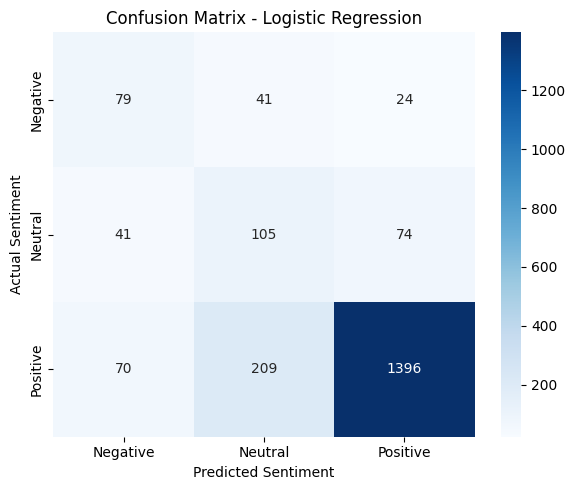

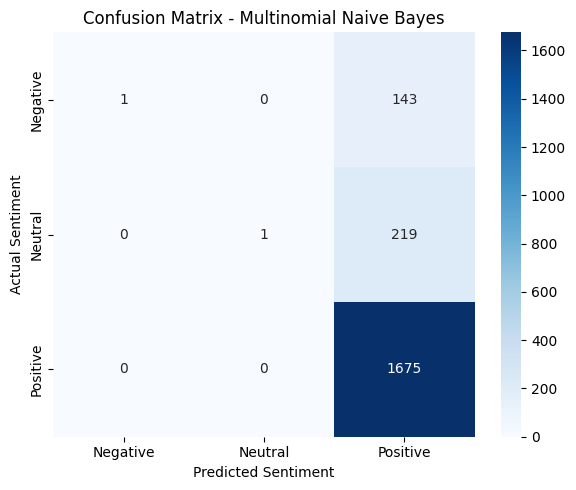

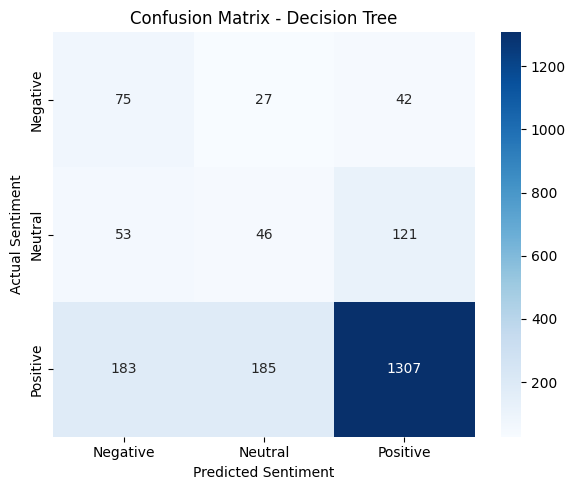

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

class_labels = ['Negative', 'Neutral', 'Positive']

for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_labels,
        yticklabels=class_labels
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Sentiment')
    plt.ylabel('Actual Sentiment')
    plt.tight_layout()
    plt.show()

In [13]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

nb_balanced = MultinomialNB()

nb_balanced.fit(
    X_train_tfidf,
    y_train,
    sample_weight=sample_weights
)

nb_balanced_pred = nb_balanced.predict(X_test_tfidf)

print("Balanced Naive Bayes Results:")
print(classification_report(
    y_test,
    nb_balanced_pred,
    labels=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

Balanced Naive Bayes Results:
              precision    recall  f1-score   support

    Negative       0.38      0.61      0.47       144
     Neutral       0.27      0.58      0.37       220
    Positive       0.95      0.76      0.85      1675

    accuracy                           0.73      2039
   macro avg       0.54      0.65      0.56      2039
weighted avg       0.84      0.73      0.77      2039



In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

all_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Naive Bayes": models["Multinomial Naive Bayes"],
    "Decision Tree": models["Decision Tree"],
    "Balanced Naive Bayes": nb_balanced
}

comparison = []

for name, model in all_models.items():

    predictions = model.predict(X_test_tfidf)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Weighted Precision": precision_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        "Weighted Recall": recall_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average='macro', zero_division=0
        )
    })

final_results = pd.DataFrame(comparison).set_index("Model")

display(final_results.round(4))

,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
Model,,,,,
Logistic Regression,0.7749,0.8289,0.7749,0.7966,0.5731
Naive Bayes,0.8225,0.8540,0.8225,0.7433,0.3084
Decision Tree,0.7003,0.7667,0.7003,0.7268,0.4511
Balanced Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624


In [15]:
final_results.to_csv("Week_05_Final_Model_Comparison.csv")

print("Final model comparison saved successfully!")

Final model comparison saved successfully!


In [16]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Balanced Naive Bayes": nb_balanced
}

cv_results = []

for name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_train_tfidf,
        y_train,
        cv=cv,
        scoring=['accuracy', 'f1_weighted', 'f1_macro'],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores['test_accuracy'].mean(),
        "Accuracy Std": scores['test_accuracy'].std(),
        "Mean Weighted F1": scores['test_f1_weighted'].mean(),
        "Mean Macro F1": scores['test_f1_macro'].mean()
    })

cv_df = pd.DataFrame(cv_results).set_index("Model")

display(cv_df.round(4))

,Mean Accuracy,Accuracy Std,Mean Weighted F1,Mean Macro F1
Model,,,,
Logistic Regression,0.7932,0.0110,0.8106,0.5971
Balanced Naive Bayes,0.8222,0.0006,0.7430,0.3099


In [17]:
cv_df.to_csv("Week_05_Cross_Validation_Results.csv")

print("Cross-validation results saved successfully!")

Cross-validation results saved successfully!


In [19]:
print("FINAL MODEL COMPARISON")
display(final_results.round(4))

print("\n5-FOLD CROSS VALIDATION")
display(cv_df.round(4))

FINAL MODEL COMPARISON


,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
Model,,,,,
Logistic Regression,0.7749,0.8289,0.7749,0.7966,0.5731
Naive Bayes,0.8225,0.8540,0.8225,0.7433,0.3084
Decision Tree,0.7003,0.7667,0.7003,0.7268,0.4511
Balanced Naive Bayes,0.7317,0.8402,0.7317,0.7691,0.5624



5-FOLD CROSS VALIDATION


,Mean Accuracy,Accuracy Std,Mean Weighted F1,Mean Macro F1
Model,,,,
Logistic Regression,0.7932,0.0110,0.8106,0.5971
Balanced Naive Bayes,0.8222,0.0006,0.7430,0.3099


In [21]:
import joblib
import os

os.makedirs("Week_05_Outputs/Models", exist_ok=True)

joblib.dump(
    models["Logistic Regression"],
    "Week_05_Outputs/Models/logistic_regression_model.pkl"
)

joblib.dump(
    tfidf,
    "Week_05_Outputs/Models/tfidf_vectorizer.pkl"
)

print("Logistic Regression model saved!")
print("TF-IDF vectorizer saved!")

Logistic Regression model saved!
TF-IDF vectorizer saved!


In [22]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

os.makedirs("Week_05_Outputs/Reports", exist_ok=True)
os.makedirs("Week_05_Outputs/Visualizations", exist_ok=True)

for name, model in all_models.items():

    predictions = model.predict(X_test_tfidf)

    safe_name = name.lower().replace(" ", "_")

    report = classification_report(
        y_test,
        predictions,
        labels=['Negative', 'Neutral', 'Positive'],
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).transpose().to_csv(
        f"Week_05_Outputs/Reports/{safe_name}_report.csv"
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=['Negative', 'Neutral', 'Positive']
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Neutral', 'Positive'],
        yticklabels=['Negative', 'Neutral', 'Positive']
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")
    plt.tight_layout()

    plt.savefig(
        f"Week_05_Outputs/Visualizations/{safe_name}_confusion_matrix.png"
    )
    plt.close()

print("Evaluation reports and confusion matrices saved!")

Evaluation reports and confusion matrices saved!


In [23]:
import shutil

shutil.make_archive(
    "Week_05_Complete_Outputs",
    "zip",
    "Week_05_Outputs"
)

print("Week 5 outputs ZIP created successfully!")

Week 5 outputs ZIP created successfully!
